# Mark Ayman

# Multi-class NN Classification




**Author:** Mark Ayman  
**Objective:** to preform full Analysis using PYTHON

## Introduction

This notebook performs a full data analysis workflow
The goal of this analysis is to:
- Understand the dataset structure
- Clean and preprocess the data
- Perform exploratory data analysis (EDA)
- Identify patterns and trends
- Generate business insights

## import libraries

In [82]:
from google.colab import files
import math
import pickle
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

## load dataset

In [83]:
# Local on collab
df = files.upload()

In [84]:
df = pd.read_csv("academic_success_sample.csv")

## Data Overview

In [85]:
df.shape

(480, 37)

In [86]:
df.columns

Index(['Marital status', 'Application mode', 'Application order', 'Course',
       'Daytime/evening attendance', 'Previous qualification',
       'Previous qualification (grade)', 'Nacionality',
       'Mother's qualification', 'Father's qualification',
       'Mother's occupation', 'Father's occupation', 'Admission grade',
       'Displaced', 'Educational special needs', 'Debtor',
       'Tuition fees up to date', 'Gender', 'Scholarship holder',
       'Age at enrollment', 'International',
       'Curricular units 1st sem (credited)',
       'Curricular units 1st sem (enrolled)',
       'Curricular units 1st sem (evaluations)',
       'Curricular units 1st sem (approved)',
       'Curricular units 1st sem (grade)',
       'Curricular units 1st sem (without evaluations)',
       'Curricular units 2nd sem (credited)',
       'Curricular units 2nd sem (enrolled)',
       'Curricular units 2nd sem (evaluations)',
       'Curricular units 2nd sem (approved)',
       'Curricular units 2nd s

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  480 non-null    int64  
 1   Application mode                                480 non-null    int64  
 2   Application order                               480 non-null    int64  
 3   Course                                          480 non-null    int64  
 4   Daytime/evening attendance                      480 non-null    int64  
 5   Previous qualification                          480 non-null    int64  
 6   Previous qualification (grade)                  480 non-null    float64
 7   Nacionality                                     480 non-null    int64  
 8   Mother's qualification                          480 non-null    int64  
 9   Father's qualification                     

In [88]:
df.nunique()

,0
Marital status,4
Application mode,13
Application order,6
Course,17
Daytime/evening attendance,2
Previous qualification,14
Previous qualification (grade),62
Nacionality,5
Mother's qualification,17
Father's qualification,13


In [89]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.00000,480.000000,480.000000,...,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000,480.000000
mean,1.116667,16.829167,1.781250,9065.460417,0.902083,4.487500,132.810833,1.35625,18.991667,22.697917,...,0.081250,0.364583,6.291667,7.918750,4.695833,10.795958,0.112500,11.563750,1.221458,0.004104
std,0.473663,17.280807,1.350815,1600.703318,0.297512,10.381645,12.346954,3.95963,15.134192,14.981074,...,0.413325,1.438509,1.845361,3.539763,2.747400,4.817300,0.566874,2.742479,1.368974,2.235312
min,1.000000,1.000000,1.000000,33.000000,0.000000,1.000000,96.000000,1.00000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9130.000000,1.000000,1.000000,125.000000,1.00000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9254.000000,1.000000,1.000000,133.000000,1.00000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.387500,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9514.000000,1.000000,1.000000,140.000000,1.00000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.512500,0.000000,13.900000,2.600000,1.790000
max,4.000000,53.000000,6.000000,9991.000000,1.000000,43.000000,188.000000,62.00000,42.000000,39.000000,...,4.000000,13.000000,19.000000,19.000000,19.000000,17.587500,6.000000,16.200000,3.700000,3.510000


In [90]:
df.describe(include = 'O')

,Target
count,480
unique,3
top,Graduate
freq,274


In [91]:
df.duplicated().sum()

np.int64(0)

In [92]:
df.isnull().sum()

,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0


### dentify Column Types

In [93]:
categorical_cols = df.select_dtypes(include=["object"]).columns
numerical_cols = df.select_dtypes(exclude=["object"]).columns

## Data Visualization

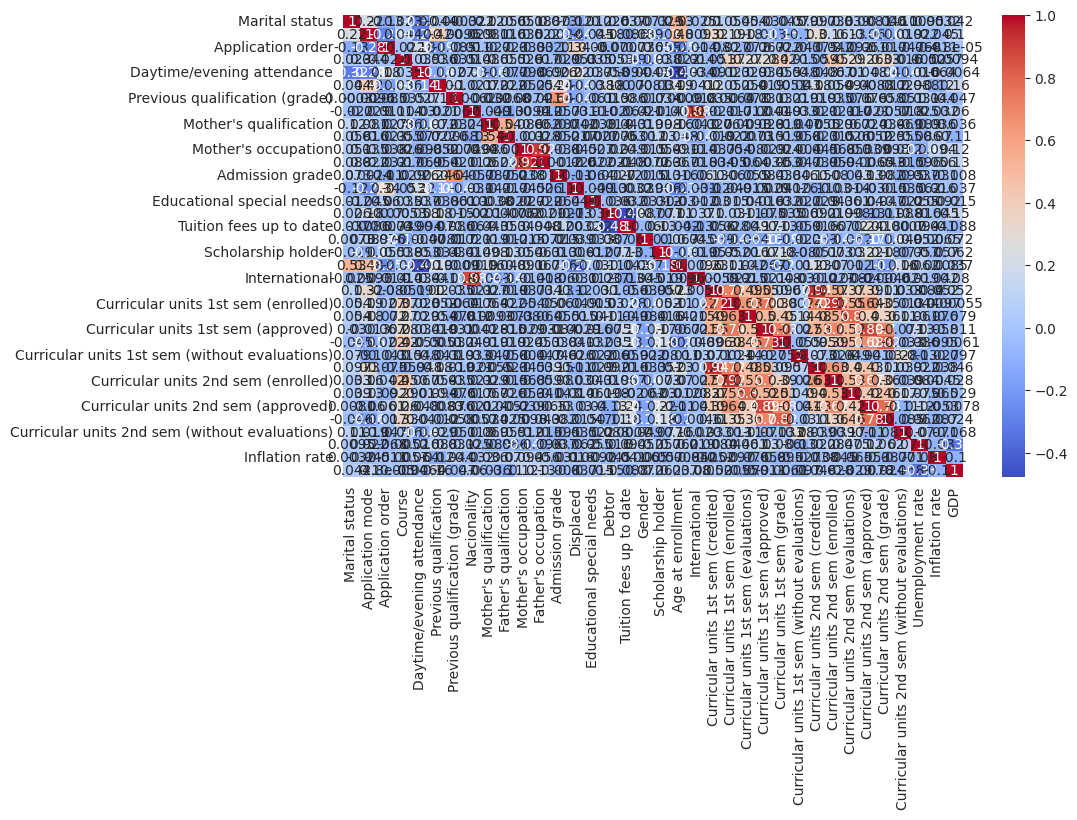

In [94]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

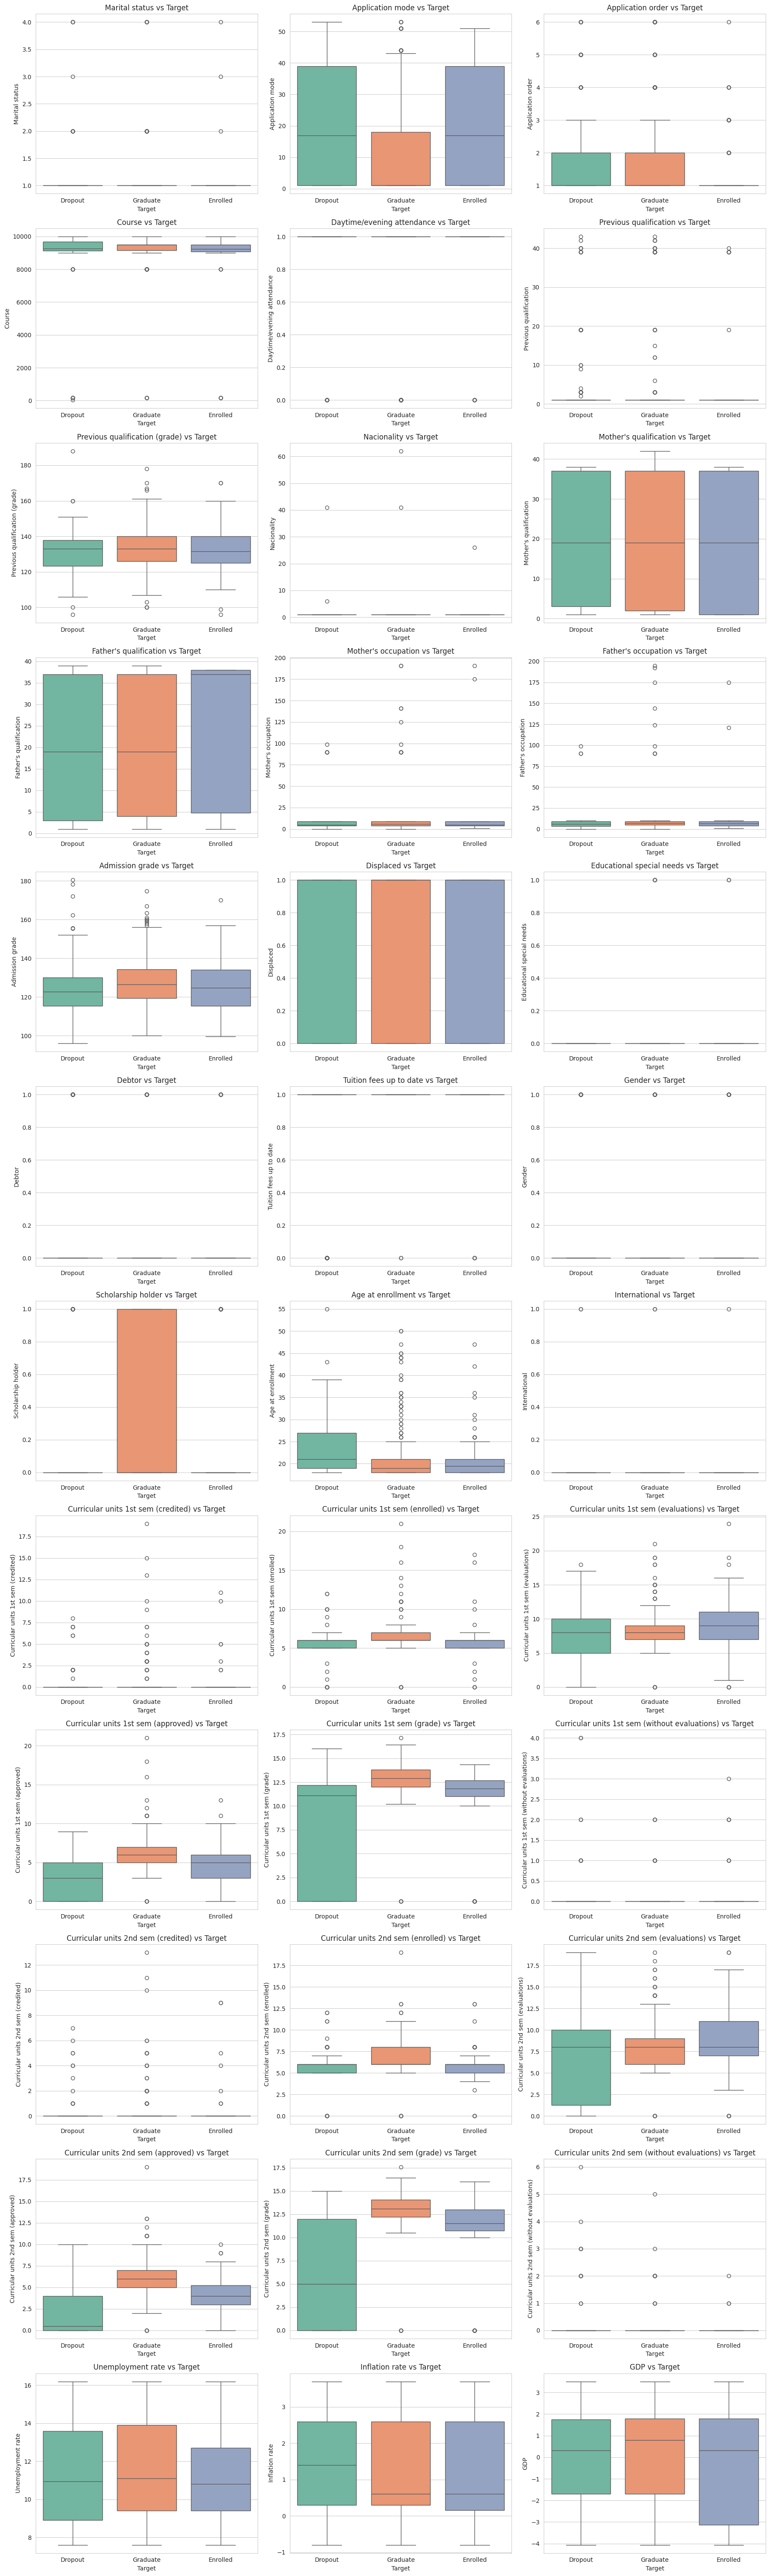

In [95]:
feature_columns = numerical_cols
target_columns = categorical_cols

sns.set_style("whitegrid")

for target in target_columns:

    n_cols = 3
    n_rows = math.ceil(len(feature_columns) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 5*n_rows))
    axes = axes.flatten()

    for ax, feature in zip(axes, feature_columns):
        sns.boxplot(
            x=target,
            y=feature,
            hue=target,
            data=df,
            ax=ax,
            palette="Set2",
            legend=False
        )

        ax.set_title(f"{feature} vs {target}")
        ax.set_xlabel(target)
        ax.set_ylabel(feature)

    plt.tight_layout()
    plt.show()

In [96]:
sns.set_style("whitegrid")

n_plots = len(numerical_cols) * (len(numerical_cols) - 1) // 2

if n_plots == 0:
    print("Need at least two numerical columns.")
else:
    n_cols = 3
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))

    if n_plots == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    plot_idx = 0

    for i in range(len(numerical_cols)):
        for j in range(i + 1, len(numerical_cols)):
            col1 = numerical_cols[i]
            col2 = numerical_cols[j]

            sns.scatterplot(
                data=df,
                x=col1,
                y=col2,
                ax=axes[plot_idx]
            )

            axes[plot_idx].set_title(f"{col1} vs {col2}")

            plot_idx += 1

    for ax in axes[plot_idx:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

Output hidden; open in https://colab.research.google.com to view.

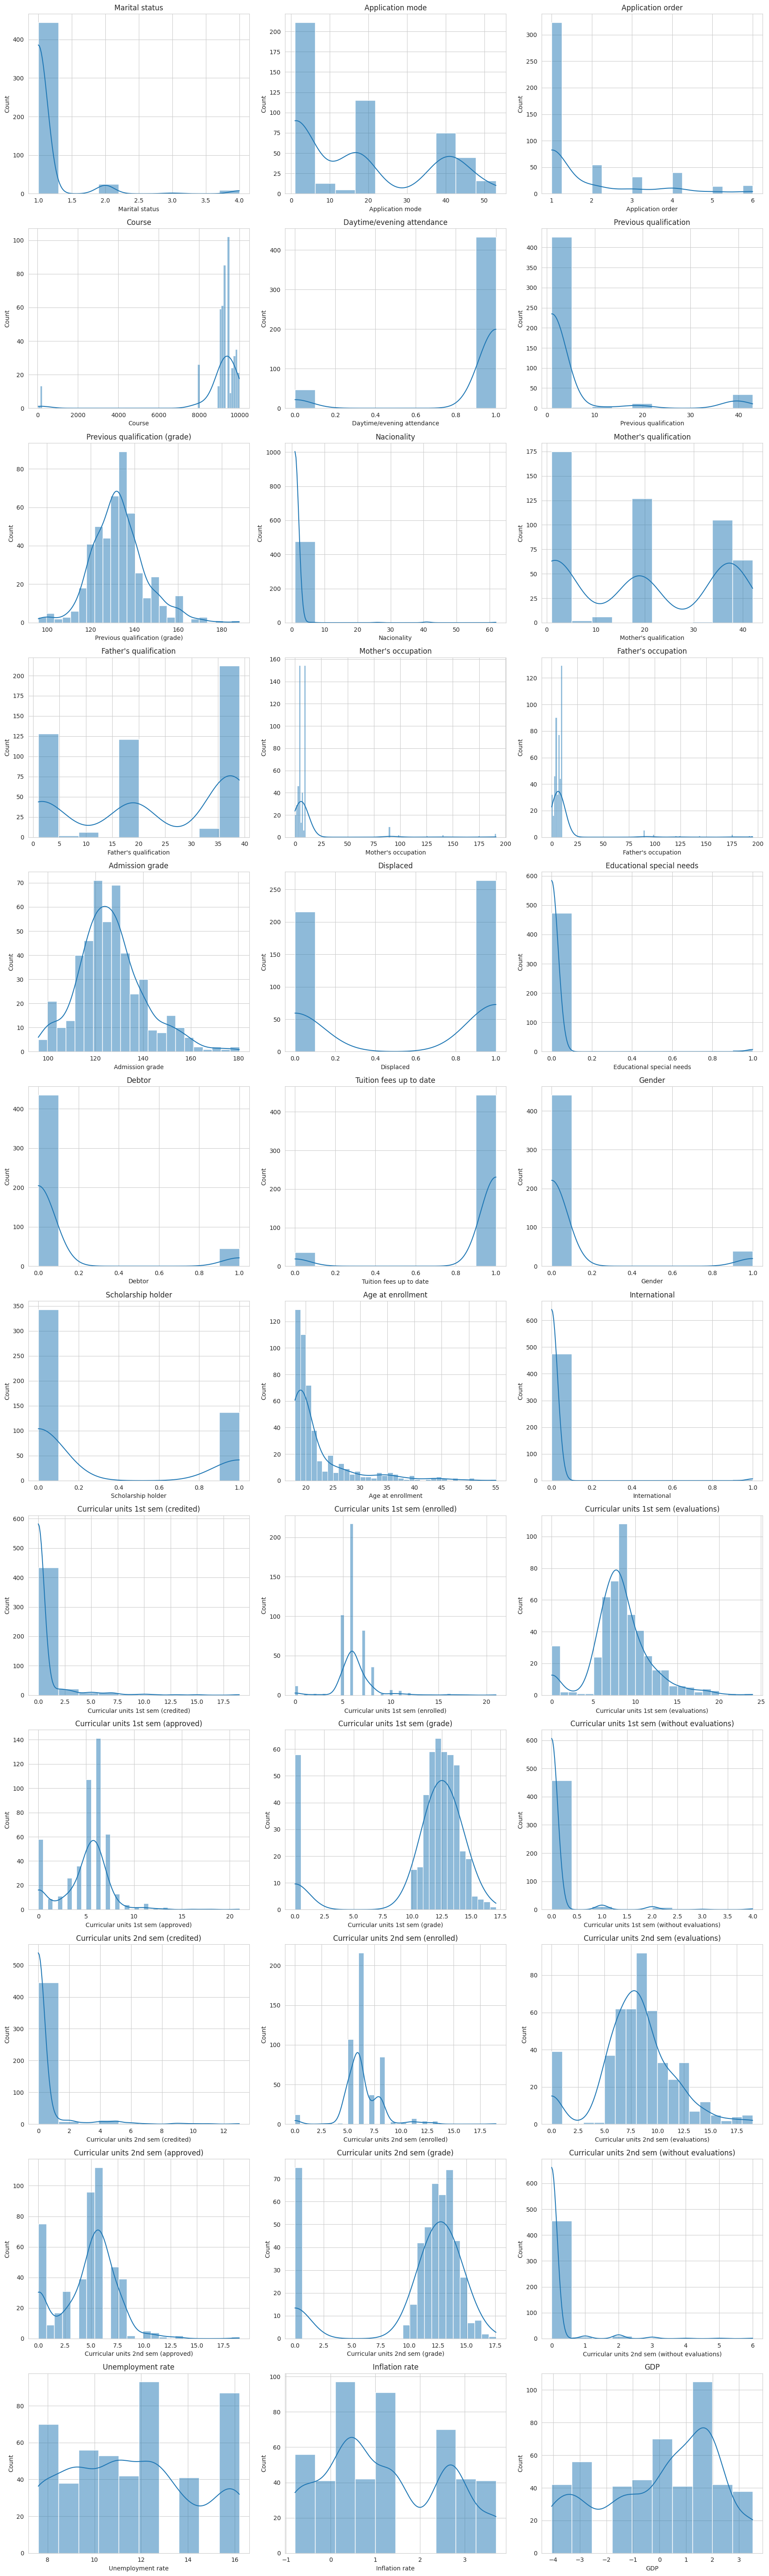

In [97]:
sns.set_style("whitegrid")

n_plots = len(numerical_cols)

if n_plots == 0:
    print("No numerical columns found.")
else:
    n_cols = 3
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))

    if n_plots == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    plot_idx = 0

    for col in numerical_cols:
        sns.histplot(
            data=df,
            x=col,
            kde=True,
            ax=axes[plot_idx]
        )

        axes[plot_idx].set_title(col)
        plot_idx += 1

    for ax in axes[plot_idx:]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

## Model

### Separate Features and Target

In [98]:
X = df.drop("Target", axis=1)
y = df["Target"]

In [99]:
categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

### Create the Preprocessing Pipeline

In [100]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

### Train-Test Split

In [101]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

X_train = X_train_processed
X_test = X_test_processed

### Select Model

In [102]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),

    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.40),

    Dense(64, activation="relu"),
    BatchNormalization(),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(3, activation="softmax")
])

In [103]:
model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [104]:
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [105]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print(class_weights)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=150,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

{np.int64(0): np.float64(1.3061224489795917), np.int64(1): np.float64(1.9104477611940298), np.int64(2): np.float64(0.5844748858447488)}
Epoch 1/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.4430 - loss: 2.0200 - val_accuracy: 0.5325 - val_loss: 1.0342
Epoch 2/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4919 - loss: 1.5485 - val_accuracy: 0.4935 - val_loss: 1.0435
Epoch 3/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4625 - loss: 1.4501 - val_accuracy: 0.3896 - val_loss: 1.0426
Epoch 4/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5765 - loss: 1.3131 - val_accuracy: 0.3766 - val_loss: 1.0411
Epoch 5/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5277 - loss: 1.2238 - val_accuracy: 0.4026 - val_loss: 1.0408
Epoch 6/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5537 - loss: 1.2020 - val_accuracy: 0.4026 - val_loss: 1.0494
Epoch 7/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5993 - loss: 1.1009 - val_accuracy:

### Train & Predict

In [106]:
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


### Evaluate

In [107]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[str(c) for c in label_encoder.classes_]
    )
)

print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

     Dropout       0.72      0.54      0.62        24
    Enrolled       0.27      0.59      0.37        17
    Graduate       0.85      0.64      0.73        55

    accuracy                           0.60        96
   macro avg       0.62      0.59      0.57        96
weighted avg       0.72      0.60      0.64        96

[[13  9  2]
 [ 3 10  4]
 [ 2 18 35]]


### Save the Pipeline

In [108]:
pipeline_bundle = {
    "preprocessor": preprocessor,
    "model": model,
}

with open("Model.pkl", "wb") as f:
    pickle.dump(pipeline_bundle, f)

## Key Insights



Based on the analysis, here are some key insights:

*   **Data Overview:** The dataset contains a mix of numerical and categorical features related to academic success. Initial checks confirmed the absence of obvious duplicates and provided an overview of data distribution and unique values.
*   **Data Quality:** Missing values were identified and handled implicitly through preprocessing steps for the model. Further investigation into specific missing value patterns could provide additional insights.
*   **Feature Importance (Implicit from Visualizations):** The box plots (`js6AH5f8dy-X`) visualized the relationship between numerical features and the 'Target' variable, indicating some features might have stronger discriminative power than others. For example, some numerical features showed distinct distributions across the different target classes.
*   **Correlations:** The heatmap (`UemRrwWsVcTa`) revealed correlations between numerical features, which is important for understanding potential multicollinearity and feature redundancy.
*   **Model Performance:** The neural network model achieved an accuracy of approximately 57.3%. The `classification_report` indicated varying precision, recall, and F1-scores across the different target classes, suggesting that the model performs better on some classes than others. Class imbalance was addressed using `compute_class_weight`, which is a good practice for this type of problem.
*   **Preprocessing Effectiveness:** The use of `StandardScaler` for numerical features and `OneHotEncoder` for categorical features, combined with `LabelEncoder` for the target, effectively transformed the raw data into a format suitable for the neural network model.

## Conclusions

This notebook successfully implemented a full data analysis workflow for predicting academic success. A multi-class classification model using a neural network was developed, trained, and evaluated. While an accuracy of 57.3% was achieved, there is room for improvement.

**Future Work:**

*   **Further Feature Engineering:** Explore creating new features from existing ones or using more advanced encoding techniques for categorical variables.
*   **Hyperparameter Tuning:** Conduct a more extensive search for optimal hyperparameters for the neural network (e.g., number of layers, neurons, activation functions, learning rate, dropout rates) using techniques like GridSearchCV or RandomizedSearchCV.
*   **Alternative Models:** Evaluate other machine learning models that were imported but not used, such as `XGBClassifier`, `RandomForestClassifier`, or `LogisticRegression`, to compare their performance against the neural network.
*   **Addressing Class Imbalance:** Although `class_weight` was used, further techniques like SMOTE for oversampling or more sophisticated undersampling methods could be explored to potentially improve performance on minority classes.
*   **Error Analysis:** Analyze the `confusion_matrix` in more detail to understand where the model is making incorrect predictions and focus efforts on improving those specific areas.